# Boiling Point Prediction and Lapse Rate Sensitivity

This notebook demonstrates a boiling point prediction experiment using the ISA barometric formula combined with the Antoine equation. It evaluates the sensitivity of boiling point predictions to changes in the atmospheric lapse rate.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# Core packages (pre-installed on Colab, install locally to match Colab env)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')
_pip('loguru==0.7.3')

In [2]:
from loguru import logger
import sys
import json
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

# Setup logging
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

# One colour per role, the same in every notebook of this run and in the paper's figures.
COLOURS = {
    "method": "#0173B2",  # the paper's own method, model or condition
    "baseline": "#949494",  # the main baseline, control or reference
    "other_1": "#DE8F05",  # the first further comparator
    "other_2": "#029E73",  # the second
    "other_3": "#CC78BC",  # the third
    "other_4": "#CA9161",  # the fourth
    "other_5": "#56B4E9",  # the fifth
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#CCCCCC",
    "grid.alpha": 0.6,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=list(COLOURS.values())),
    "image.cmap": "cividis",
    "legend.frameon": False,
    "figure.constrained_layout.use": True,
    "figure.dpi": 120,
})

Matplotlib is building the font cache; this may take a moment.


In [3]:
import http.client
import json
import urllib.request
from pathlib import Path

GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-daa948-boiling-point-prediction-error-as/main/round-2/experiment-4/demo/mini_demo_data.json"

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

data = load_data()

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found


## Config
Set the parameters for the boiling point prediction experiment.

In [4]:
NUM_SENSITIVITY_POINTS = 31
LAPSE_RATE_RANGE = (0.005, 0.008)

## Processing
Define the physical models and run the sensitivity analysis.

In [5]:
def barometric_formula(altitude, lapse_rate=0.0065, T0=288.15, P0=101325):
    return P0 * (1 - (lapse_rate * altitude / T0))**(9.80665 / (287.05 * lapse_rate))

def antoine_equation(pressure_pa):
    p_mmhg = pressure_pa / 133.322
    A, B, C = 8.07131, 1730.63, 233.426
    T_c = B / (A - np.log10(p_mmhg)) - C
    return T_c

def compute_rmse(predictions, observations):
    return float(np.sqrt(np.mean((np.array(predictions) - np.array(observations))**2)))

altitudes = np.array([d["altitude"] for d in data])
observed_temps = np.array([d["boiling_point"] for d in data])

baseline_lr = 0.0065
baseline_pressures = barometric_formula(altitudes, lapse_rate=baseline_lr)
baseline_predictions = np.array([antoine_equation(p) for p in baseline_pressures])
baseline_rmse = compute_rmse(baseline_predictions, observed_temps)

lapse_rates = np.linspace(LAPSE_RATE_RANGE[0], LAPSE_RATE_RANGE[1], NUM_SENSITIVITY_POINTS)
sensitivity_results = []
for lr in lapse_rates:
    pressures = barometric_formula(altitudes, lapse_rate=lr)
    predictions = np.array([antoine_equation(p) for p in pressures])
    rmse = compute_rmse(predictions, observed_temps)
    sensitivity_results.append({'lr': lr, 'rmse': rmse})

## Results
Visualize the sensitivity analysis results.

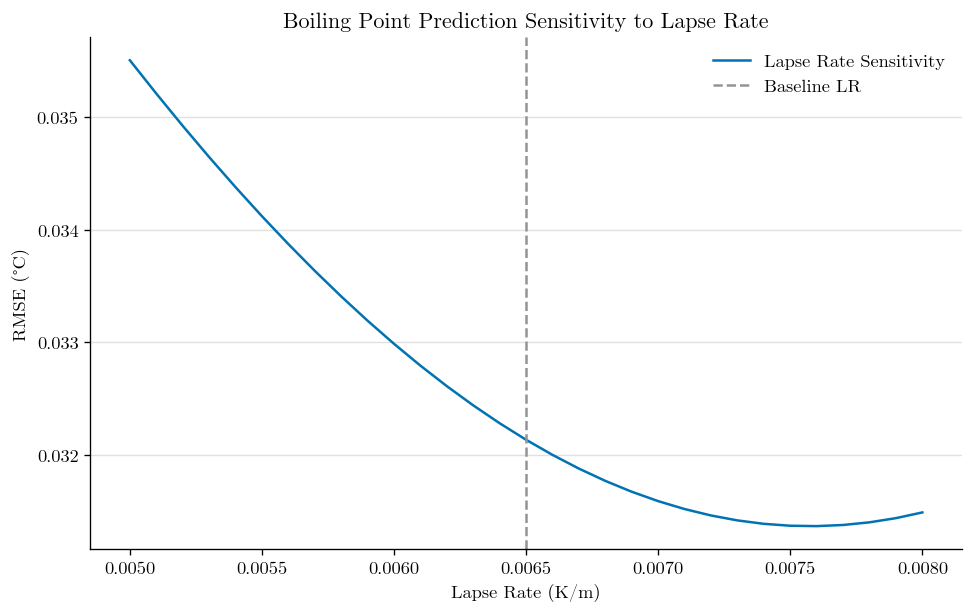

In [6]:
lrs = [r['lr'] for r in sensitivity_results]
rmses = [r['rmse'] for r in sensitivity_results]

plt.figure(figsize=(8, 5))
plt.plot(lrs, rmses, color=COLOURS["method"], label="Lapse Rate Sensitivity")
plt.axvline(baseline_lr, color=COLOURS["baseline"], linestyle="--", label="Baseline LR")
plt.xlabel("Lapse Rate (K/m)")
plt.ylabel("RMSE (°C)")
plt.title("Boiling Point Prediction Sensitivity to Lapse Rate")
plt.legend()
plt.show()